# Кластерный анализ в Python

**Дисциплина:** Введение в анализ больших данных

**Кластеризация** — разбиение объектов на группы так, чтобы внутри группы объекты были похожи, а между группами — различались.

Методы:
1. **Иерархические** — дендрограмма, `linkage` + `fcluster`
2. **Нейерархические** — k-means (число кластеров задаётся заранее)

Перед кластеризацией признаки обычно **стандартизируют**.

Демо: **penguins** (морфометрия).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)


---
## 1. Данные и стандартизация


In [9]:
kl = pd.read_csv('Klaster.csv', sep=';', decimal=',')
kl.info()


<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   vid            11 non-null     str    
 1   temper         11 non-null     float64
 2   rashodEnerdgi  11 non-null     float64
 3   otnPoverhnost  11 non-null     float64
 4   massa          11 non-null     float64
 5   mozg           11 non-null     float64
 6   pochki         11 non-null     float64
 7   pechen         11 non-null     float64
 8   selezenka      11 non-null     float64
 9   mishzi         11 non-null     float64
dtypes: float64(9), str(1)
memory usage: 1012.0 bytes


In [10]:
animal_names = kl['vid'].values
kl_numeric = kl.drop('vid', axis=1)


In [13]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(kl_numeric),
    columns=kl_numeric.columns,
    index=kl_numeric.index,
)
print(X_scaled.head().round(3))
print("средние ≈ 0:", X_scaled.mean().round(3).tolist())
print("ст.откл. ≈ 1:", X_scaled.std(ddof=0).round(3).tolist())


   temper  rashodEnerdgi  otnPoverhnost  massa   mozg  pochki  pechen  \
0   0.597         -0.650          1.309 -0.677  1.869   2.111   2.410   
1   0.445         -0.650          0.483 -0.676  0.633   1.168   1.151   
2   0.445         -0.649         -0.130 -0.675  0.820   0.405   0.254   
3   0.750         -0.647         -0.329 -0.673  0.989   0.727  -0.045   
4   0.750         -0.641         -0.044 -0.665  0.745  -0.681   0.297   

   selezenka  mishzi  
0      1.953   2.310  
1      0.939   0.873  
2      0.674   0.830  
3      1.301   0.619  
4     -0.099  -1.115  
средние ≈ 0: [0.0, 0.0, -0.0, 0.0, 0.0, -0.0, -0.0, 0.0, -0.0]
ст.откл. ≈ 1: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


Всех уравняли, чтобы кластеризация не пошла по самому большому значению.

---
## 2. Иерархическая кластеризация

`linkage(X, method="ward")` → дендрограмма → `fcluster(..., criterion="maxclust")`.


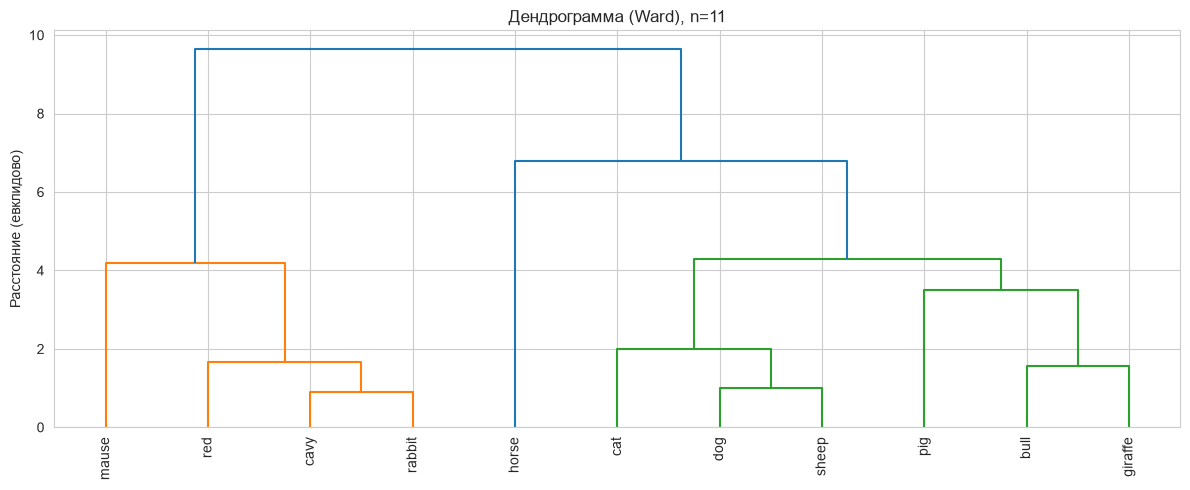

In [14]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, labels=animal_names, leaf_rotation=90, leaf_font_size=10)
plt.title("Дендрограмма (Ward), n=11")
plt.ylabel("Расстояние (евклидово)")
plt.tight_layout()
plt.show()


3 кластера можно оставить (по цветам), они наиболее биологически обоснованы

In [15]:
features = kl_numeric.columns.tolist()

Z_full = linkage(X_scaled, method="ward")
labels_h = fcluster(Z_full, t=3, criterion="maxclust")

kl_h = kl.copy()
kl_h["cluster_h"] = labels_h

print("=== ИЕРАРХИЧЕСКАЯ КЛАСТЕРИЗАЦИЯ ===")
print("Размеры кластеров:")
print(kl_h["cluster_h"].value_counts().sort_index())
print("\nСредние признаков по кластерам:")
print(kl_h.groupby("cluster_h")[features].mean().round(1))
print("\n")


=== ИЕРАРХИЧЕСКАЯ КЛАСТЕРИЗАЦИЯ ===
Размеры кластеров:
cluster_h
1    4
2    6
3    1
Name: count, dtype: int64

Средние признаков по кластерам:
           temper  rashodEnerdgi  otnPoverhnost  massa  mozg  pochki  pechen  \
cluster_h                                                                      
1            37.9            0.4           21.2    0.5  28.7    37.7    16.2   
2            37.5           95.3           14.6  164.6  20.3    23.4     9.9   
3            36.3          468.2           35.7  725.0  15.7    21.5     5.4   

           selezenka  mishzi  
cluster_h                     
1               13.8     9.3  
2                6.2     5.1  
3                4.2     4.4  




---
## 3. K-means

Число кластеров: **elbow** (inertia) и **silhouette**.


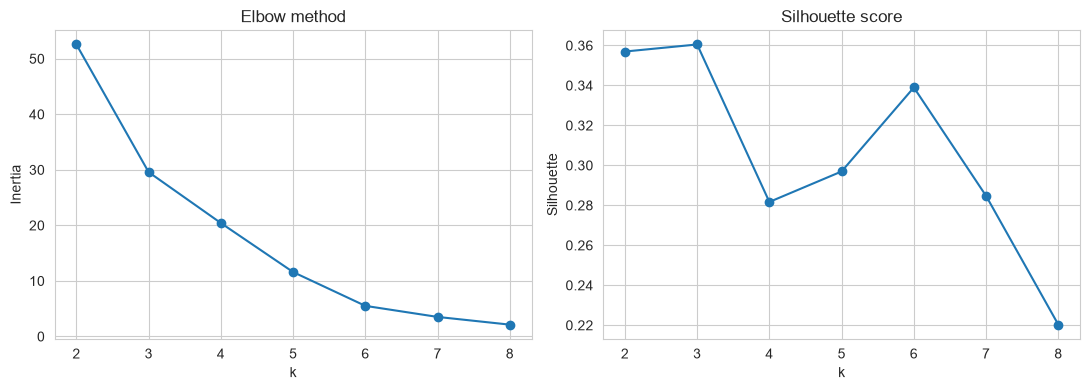

In [17]:
inertias, silhouettes = [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lab))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(K_range), inertias, "o-")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
axes[1].plot(list(K_range), silhouettes, "o-")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette score")
plt.tight_layout()
plt.show()


По методу локтя сложно определить из-за размера выборки, однако можно взять k=3, по Silhouette это будет 0.36 - пик

In [18]:
k_opt = 3
km = KMeans(n_clusters=k_opt, n_init=25, random_state=42)
labels_km = km.fit_predict(X_scaled)

kl_km = kl.copy()
kl_km["cluster"] = labels_km + 1

print("=== KMEANS КЛАСТЕРИЗАЦИЯ (k=3) ===")
print("Размеры:", kl_km["cluster"].value_counts().sort_index().to_dict())
print("\nЦентры (в стандартизированных координатах):")
print(pd.DataFrame(km.cluster_centers_, columns=features).round(3))
print("\nСредние в исходных единицах:")
print(kl_km.groupby("cluster")[features].mean().round(1))


=== KMEANS КЛАСТЕРИЗАЦИЯ (k=3) ===
Размеры: {1: 4, 2: 1, 3: 6}

Центры (в стандартизированных координатах):
   temper  rashodEnerdgi  otnPoverhnost  massa   mozg  pochki  pechen  \
0   0.559         -0.649          0.333 -0.675  1.078   1.103   0.942   
1  -1.848          2.570          2.392  2.473 -1.351  -0.824  -1.368   
2  -0.065          0.004         -0.621  0.038 -0.493  -0.598  -0.400   

   selezenka  mishzi  
0      1.217   1.158  
1     -1.113  -0.903  
2     -0.626  -0.621  

Средние в исходных единицах:
         temper  rashodEnerdgi  otnPoverhnost  massa  mozg  pochki  pechen  \
cluster                                                                      
1          37.9            0.4           21.2    0.5  28.7    37.7    16.2   
2          36.3          468.2           35.7  725.0  15.7    21.5     5.4   
3          37.5           95.3           14.6  164.6  20.3    23.4     9.9   

         selezenka  mishzi  
cluster                     
1             13.8     9.3  

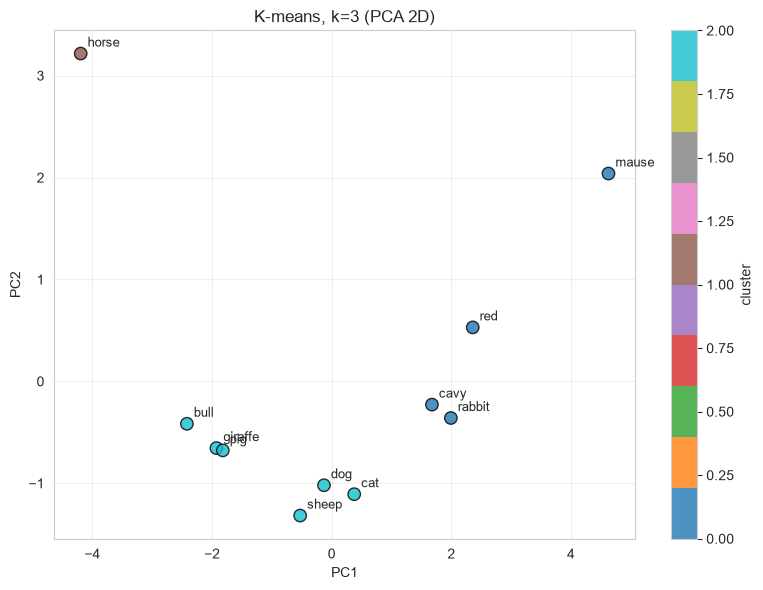

Доля дисперсии PC1+PC2: 0.856
PC1: 0.653
PC2: 0.202


In [19]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sc = plt.scatter(coords[:, 0], coords[:, 1], c=labels_km, cmap="tab10",
                 s=80, edgecolors="k", alpha=0.8)

for i, name in enumerate(animal_names):
    plt.annotate(name, (coords[i, 0], coords[i, 1]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"K-means, k={k_opt} (PCA 2D)")
plt.colorbar(sc, label="cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Доля дисперсии PC1+PC2:", round(pca.explained_variance_ratio_.sum(), 3))
print("PC1:", round(pca.explained_variance_ratio_[0], 3))
print("PC2:", round(pca.explained_variance_ratio_[1], 3))


### Вывод
Оптимальное число кластеров (k=3) подтверждено методом силуэта (max ≈ 0.36). Метод локтя на малой выборке менее информативен, но тоже указывает на k=3

Кластер 1 (mause, red, cavy, rabbit)
> мелкие животные с высокой относительной поверхностью и большим процентом мозга/почек. Это соответствует известному биологическому факту: у мелких животных интенсивнее метаболизм

Кластер 2 (horse)
> лошадь выделяется в отдельный кластер из-за экстремальных значений массы и расхода энергии.

Кластер 3 (cat, dog, sheep, pig, bull, giraffe)
> средние и крупные животные со сбалансированными показателями.

Доля дисперсии PC1+PC2: 0.856 - почти 86% информации из 9D удалось сохранить в 2D

### Как описать результаты

1. Обоснуйте число кластеров (дендрограмма / elbow / silhouette).  
2. Опишите **профили** кластеров (средние признаков).  
3. При необходимости визуализируйте в PCA-плоскости.

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Стандартизация | `StandardScaler().fit_transform(X)` |
| Иерархия | `linkage(X, method="ward")` |
| Дендрограмма | `dendrogram(Z, labels=...)` |
| Срез на k групп | `fcluster(Z, t=k, criterion="maxclust")` |
| K-means | `KMeans(n_clusters=k, n_init=10).fit(X)` |
| Метки / центры | `km.labels_`, `km.cluster_centers_` |
| Inertia | `km.inertia_` |
| Silhouette | `silhouette_score(X, labels)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните кластеризацию **самостоятельно**.  
2. Всегда стандартизируйте признаки перед расчётом расстояний.

Удачи!
